### Load the cleaned dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "online_retail_cleaned.csv"
)

df = pd.read_csv(DATA_PATH, parse_dates=["InvoiceDate"])

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Cleaned dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Cleaned dataset loaded successfully!
Shape: (536641, 14)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsReturnCandidate,IsZeroPrice,IsNegativePrice,TransactionType,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,False,False,False,False,Sale,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,False,Sale,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,False,False,False,False,Sale,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,False,Sale,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,False,Sale,20.34


### Prepare separate analysis datasets

In [2]:
sales_df = df[df["TransactionType"] == "Sale"].copy()

returns_df = df[df["TransactionType"] == "Potential Return"].copy()

cancelled_df = df[
    df["TransactionType"] == "Cancelled Invoice"
].copy()

zero_price_df = df[
    df["IsZeroPrice"] == True
].copy()

print("Normal sales records:", len(sales_df))
print("Potential return records:", len(returns_df))
print("Cancelled invoice records:", len(cancelled_df))
print("Zero-price records:", len(zero_price_df))

Normal sales records: 524878
Potential return records: 1336
Cancelled invoice records: 9251
Zero-price records: 2510


### Calculate key business metrics

In [3]:
total_revenue = sales_df["Revenue"].sum()

total_orders = sales_df["InvoiceNo"].nunique()

total_products_sold = sales_df["Quantity"].sum()

unique_customers = sales_df["CustomerID"].nunique()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)

print("========== BUSINESS KPI SUMMARY ==========")

print(f"Total Sales Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Products Sold: {total_products_sold:,}")
print(f"Unique Identified Customers: {unique_customers:,}")
print(f"Average Order Value: {average_order_value:,.2f}")

========== BUSINESS KPI SUMMARY ==========
Total Sales Revenue: 10,642,110.80
Total Orders: 19,960
Total Products Sold: 5,572,420
Unique Identified Customers: 4,338
Average Order Value: 533.17


### Monthly revenue analysis

In [4]:
sales_df["YearMonth"] = (
    sales_df["InvoiceDate"].dt.to_period("M")
)

monthly_sales = (
    sales_df.groupby("YearMonth")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Quantity_Sold=("Quantity", "sum")
    )
    .reset_index()
)

monthly_sales["YearMonth"] = (
    monthly_sales["YearMonth"].astype(str)
)

display(monthly_sales)

,YearMonth,Revenue,Orders,Quantity_Sold
0,2010-12,"821,452.73",1559,358019
1,2011-01,"689,811.61",1086,387099
2,2011-02,"522,545.56",1100,282934
3,2011-03,"716,215.26",1454,376599
4,2011-04,"536,968.49",1246,307953
5,2011-05,"769,296.61",1681,395001
6,2011-06,"760,547.01",1533,388511
7,2011-07,"718,076.12",1475,399693
8,2011-08,"757,841.38",1361,421020
9,2011-09,"1,056,435.19",1837,569573


### Visualize monthly revenue

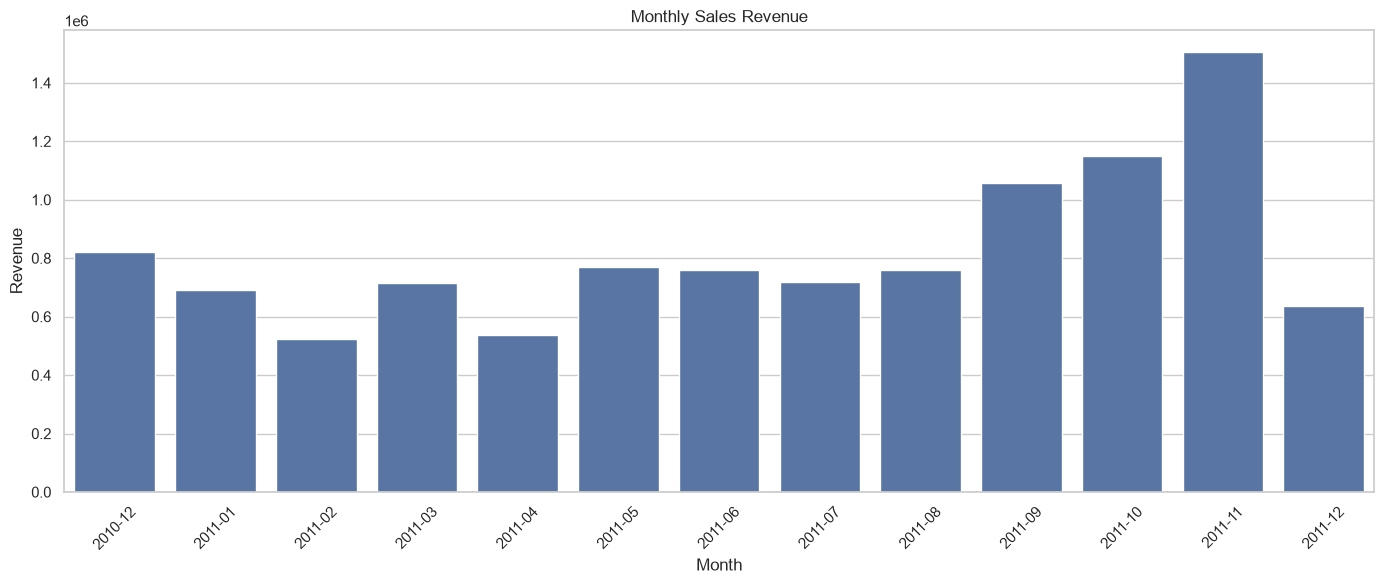

In [5]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=monthly_sales,
    x="YearMonth",
    y="Revenue"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Top 10 products by revenue

,Description,Revenue,Quantity_Sold
0,DOTCOM POSTAGE,"206,248.77",706
1,REGENCY CAKESTAND 3 TIER,"174,156.54",13851
2,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995
3,WHITE HANGING HEART T-LIGHT HOLDER,"106,236.72",37872
4,PARTY BUNTING,"99,445.23",18283
5,JUMBO BAG RED RETROSPOT,"94,159.81",48371
6,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033
7,POSTAGE,"78,101.88",3150
8,Manual,"77,752.82",6985
9,RABBIT NIGHT LIGHT,"66,870.03",30739


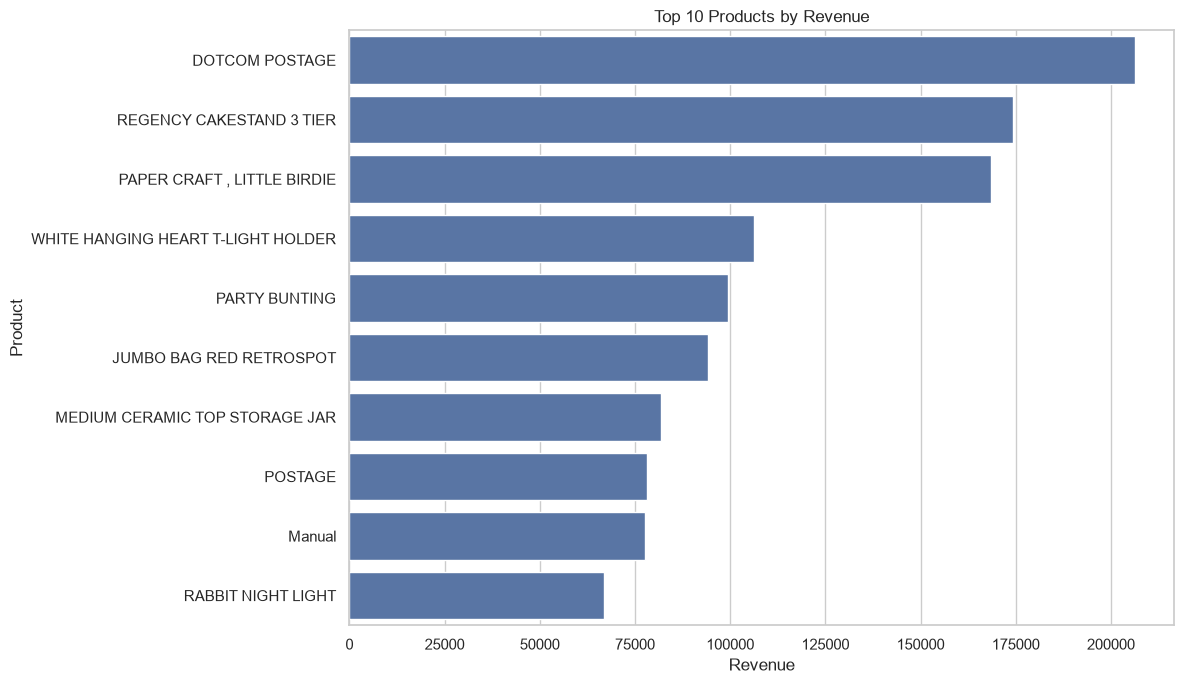

In [6]:
top_products = (
    sales_df.groupby("Description")
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

### Country-wise revenue analysis

,Country,Revenue,Orders,Quantity_Sold
0,United Kingdom,"9,001,744.09",18019,4646906
1,Netherlands,"285,446.34",94,200361
2,EIRE,"283,140.52",288,147007
3,Germany,"228,678.40",457,119154
4,France,"209,625.37",392,112060
5,Australia,"138,453.81",57,83891
6,Spain,"61,558.56",90,27933
7,Switzerland,"57,067.60",54,30617
8,Belgium,"41,196.34",98,23237
9,Sweden,"38,367.83",36,36078


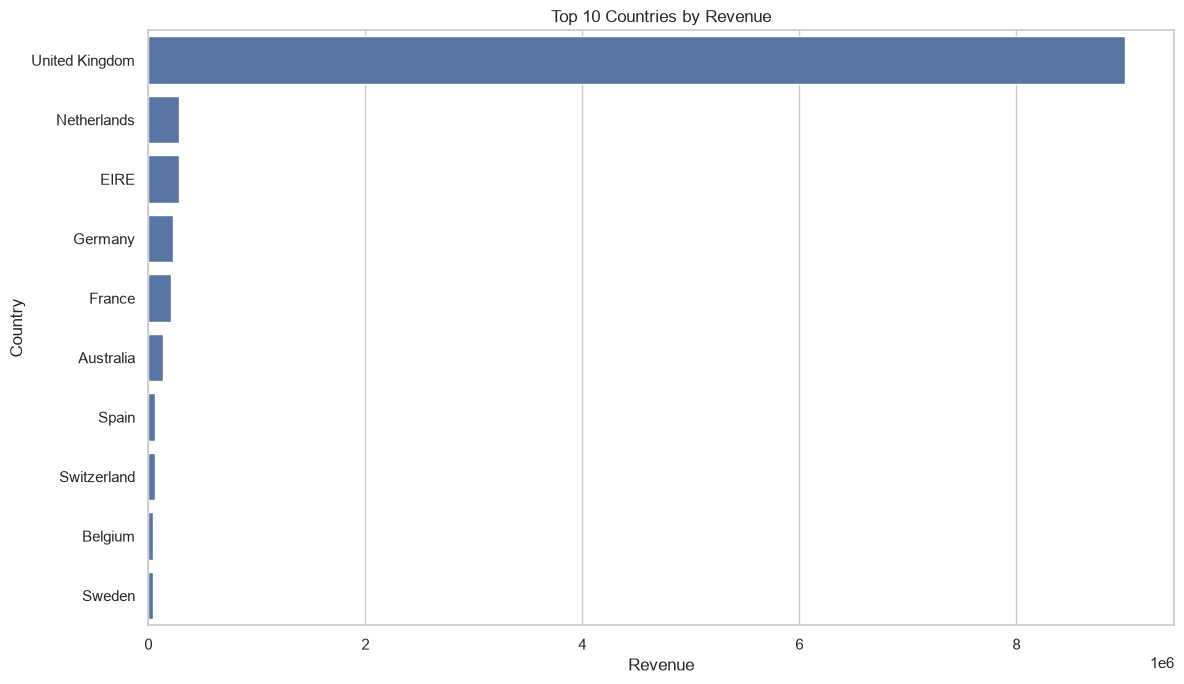

In [7]:
country_sales = (
    sales_df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .reset_index()
)

display(country_sales.head(15))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_sales.head(10),
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Top 10 customers by revenue

In [8]:
customer_sales = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(customer_sales)

,CustomerID,Revenue,Orders,Quantity_Sold
0,"14,646.00","280,206.02",73,196915
1,"18,102.00","259,657.30",60,64124
2,"17,450.00","194,390.79",46,69973
3,"16,446.00","168,472.50",2,80997
4,"14,911.00","143,711.17",201,80240
5,"12,415.00","124,914.53",21,77374
6,"14,156.00","117,210.08",55,57768
7,"17,511.00","91,062.38",31,64549
8,"16,029.00","80,850.84",63,40108
9,"12,346.00","77,183.60",1,74215


### Correctly display top customers

In [9]:
customer_sales = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(customer_sales)

,CustomerID,Revenue,Orders,Quantity_Sold
0,"14,646.00","280,206.02",73,196915
1,"18,102.00","259,657.30",60,64124
2,"17,450.00","194,390.79",46,69973
3,"16,446.00","168,472.50",2,80997
4,"14,911.00","143,711.17",201,80240
5,"12,415.00","124,914.53",21,77374
6,"14,156.00","117,210.08",55,57768
7,"17,511.00","91,062.38",31,64549
8,"16,029.00","80,850.84",63,40108
9,"12,346.00","77,183.60",1,74215


### Monthly order and revenue trends

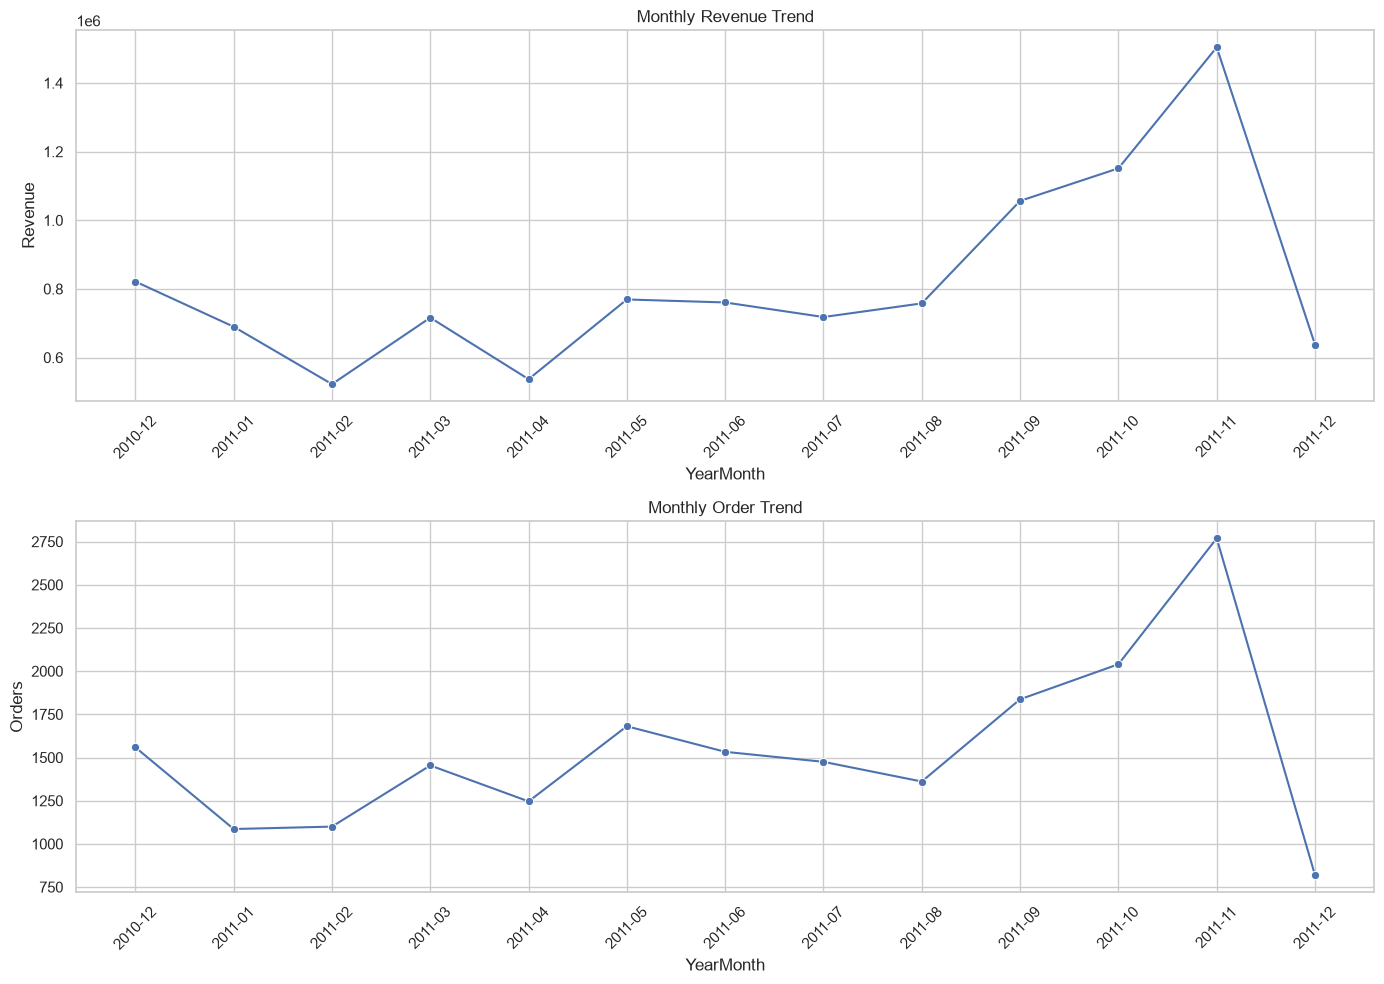

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Revenue",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Monthly Revenue Trend")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Orders",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Monthly Order Trend")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Revenue contribution by country

In [11]:
top_5_countries = country_sales.head(5).copy()

top_5_countries["Revenue Share (%)"] = (
    top_5_countries["Revenue"]
    / country_sales["Revenue"].sum()
    * 100
)

display(top_5_countries[
    ["Country", "Revenue", "Revenue Share (%)"]
])

,Country,Revenue,Revenue Share (%)
0,United Kingdom,"9,001,744.09",84.59
1,Netherlands,"285,446.34",2.68
2,EIRE,"283,140.52",2.66
3,Germany,"228,678.40",2.15
4,France,"209,625.37",1.97


### Prepare RFM data

In [12]:
# Use identified customers and normal sales only
rfm_data = sales_df.dropna(subset=["CustomerID"]).copy()

# Reference date: one day after the latest transaction
snapshot_date = rfm_data["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = rfm_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM analysis dataset created!")
print("Reference Date:", snapshot_date)
print("Customers:", len(rfm))

display(rfm.head(10))

RFM analysis dataset created!
Reference Date: 2011-12-10 12:50:00
Customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,"12,346.00",326,1,"77,183.60"
1,"12,347.00",2,7,"4,310.00"
2,"12,348.00",75,4,"1,797.24"
3,"12,349.00",19,1,"1,757.55"
4,"12,350.00",310,1,334.40
5,"12,352.00",36,8,"2,506.04"
6,"12,353.00",204,1,89.00
7,"12,354.00",232,1,"1,079.40"
8,"12,355.00",214,1,459.40
9,"12,356.00",23,3,"2,811.43"


### Assign RFM scores

In [13]:
# Rank values first to handle tied values safely
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,"12,346.00",326,1,"77,183.60",1,1,5,115
1,"12,347.00",2,7,"4,310.00",5,5,5,555
2,"12,348.00",75,4,"1,797.24",2,4,4,244
3,"12,349.00",19,1,"1,757.55",4,1,4,414
4,"12,350.00",310,1,334.40,1,1,2,112
5,"12,352.00",36,8,"2,506.04",3,5,5,355
6,"12,353.00",204,1,89.00,1,1,1,111
7,"12,354.00",232,1,"1,079.40",1,1,4,114
8,"12,355.00",214,1,459.40,1,1,2,112
9,"12,356.00",23,3,"2,811.43",4,3,5,435


### Create customer segments

In [14]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"

    else:
        return "Potential Loyalists"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

display(
    rfm["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer Segment")
    .reset_index(name="Customer Count")
)

,Customer Segment,Customer Count
0,Lost Customers,1074
1,Champions,942
2,Potential Loyalists,843
3,At Risk,661
4,Loyal Customers,508
5,Recent Customers,310


### Visualize customer segments

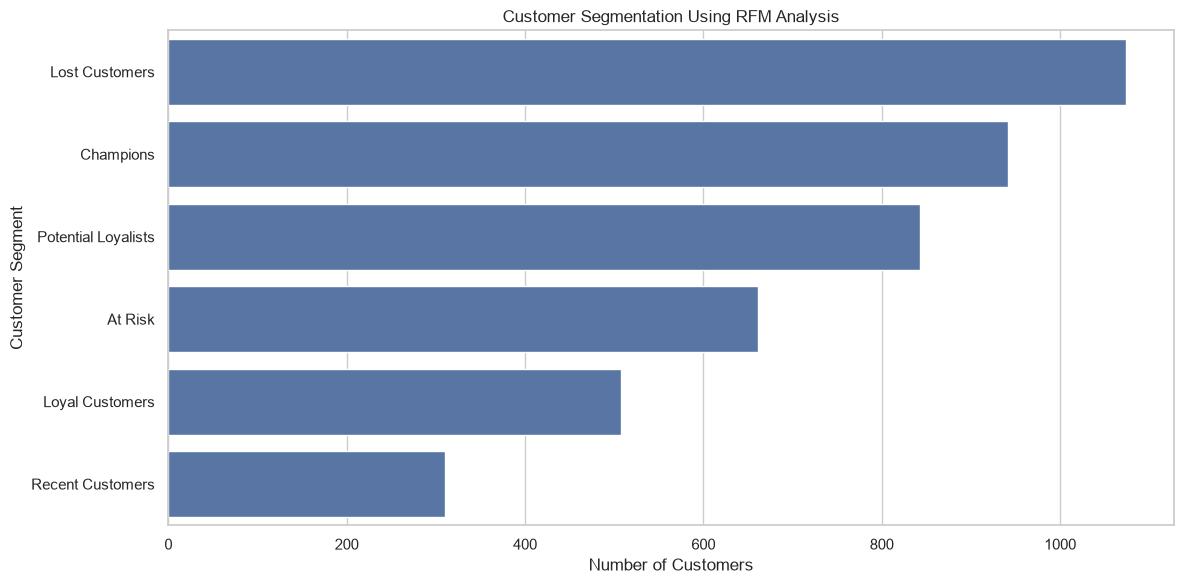

In [15]:
segment_counts = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_counts.columns = ["Customer_Segment", "Customer_Count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_counts,
    x="Customer_Count",
    y="Customer_Segment"
)

plt.title("Customer Segmentation Using RFM Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

### Segment-level business summary

In [16]:
segment_summary = rfm.groupby("Customer_Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).sort_values("Total_Revenue", ascending=False)

display(segment_summary.round(2))

,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
Customer_Segment,,,,,
Champions,942,12.50,11.20,"6,091.24","5,737,952.12"
Loyal Customers,508,37.21,5.12,"1,826.03","927,623.75"
At Risk,661,150.64,3.41,"1,246.46","823,912.44"
Potential Loyalists,843,38.97,1.85,867.95,"731,677.86"
Lost Customers,1074,216.68,1.10,487.71,"523,803.28"
Recent Customers,310,18.10,1.25,458.84,"142,239.44"


### Save the RFM results

In [19]:

# Export customer-level RFM analysis
rfm_output = (
    PROJECT_ROOT / "data" / "processed" / "customer_rfm.csv"
)

rfm.to_csv(rfm_output, index=False)

# Export segment-level summary
segment_output = (
    PROJECT_ROOT / "data" / "processed" / "rfm_segment_summary.csv"
)

segment_summary.to_csv(
    segment_output,
    index=True,
    index_label="Customer_Segment"
)

print("RFM files exported successfully!")
print("Customer RFM:", rfm_output)
print("Segment summary:", segment_output)

RFM files exported successfully!
Customer RFM: d:\Data Analyst project\retail-sales-analytics\data\processed\customer_rfm.csv
Segment summary: d:\Data Analyst project\retail-sales-analytics\data\processed\rfm_segment_summary.csv
